# Assignment 1 — training pipeline

Predicts hourly bike rentals (Seoul Bike Sharing data, used as a stand-in for
BiciMAD demand planning) with **linear regression**, trained three ways on the
same split: scikit-learn, a manual PyTorch loop, and `nn.Module` + `torch.optim`.

Run end to end with `uv run python main.py train`. Everything the dashboard
needs is written to `artifacts/`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # run as a script: save figures, never open windows

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

from features import build_features, load_clean

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

ARTIFACTS = Path("artifacts")
FIG_DIR = ARTIFACTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "figure.dpi": 110,
})


def show(fig, name):
    """Save a figure to artifacts/figures and display it when in a notebook."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    if IN_NOTEBOOK:
        from IPython.display import display
        display(fig)
    plt.close(fig)

## 1. Load and clean
Drops non-functioning days (no bikes could be rented) and adds a weekend flag.
See `features.py`.

In [2]:
df = load_clean()
print(f"{len(df)} rows, {df['date'].nunique()} days, "
      f"{df['date'].min().date()} to {df['date'].max().date()}")
df.head()

8465 rows, 353 days, 2017-12-01 to 2018-11-30


,date,count,hour,temp,humidity,wind,visibility,dew_point,solar,rain,snow,season,holiday,weekend
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,0
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,0
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,0
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,0
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,0


## 2. Features
Chosen after the EDA in `eda.ipynb`. Kept: cyclical hour (two sin/cos pairs), weekend flag, weekend × hour
interactions, holiday, temperature, solar radiation, rainfall, snowfall,
one-hot season. Dropped: humidity, wind, visibility, dew point.

In [3]:
X_all = build_features(df)
FEATURES = list(X_all.columns)
y_count = df["count"].to_numpy(dtype=float)
print(len(FEATURES), "features:", FEATURES)

17 features: ['hour_sin1', 'hour_cos1', 'hour_sin2', 'hour_cos2', 'weekend', 'weekend_x_hour_sin1', 'weekend_x_hour_cos1', 'weekend_x_hour_sin2', 'weekend_x_hour_cos2', 'holiday', 'temp', 'solar', 'rain', 'snow', 'season_spring', 'season_summer', 'season_winter']


## 3. Split by whole days
Days (not hours) are shuffled and assigned to train / validation / test
(70 / 15 / 15), so every hour of a given day lands in the same set.

In [4]:
rng = np.random.default_rng(SEED)
days = rng.permutation(df["date"].drop_duplicates().to_numpy())
n_train, n_val = int(0.70 * len(days)), int(0.15 * len(days))
split_of_day = {d: "train" for d in days[:n_train]}
split_of_day |= {d: "val" for d in days[n_train:n_train + n_val]}
split_of_day |= {d: "test" for d in days[n_train + n_val:]}
df["split"] = df["date"].map(split_of_day)

masks = {s: (df["split"] == s).to_numpy() for s in ["train", "val", "test"]}
print(df.groupby("split").agg(days=("date", "nunique"), rows=("count", "size")).to_string())
print()
print(pd.crosstab(df["season"], df["split"]).to_string())

# Standardise using training statistics only (no information from val/test).
scaler = StandardScaler().fit(X_all[masks["train"]])
X = {s: scaler.transform(X_all[m]) for s, m in masks.items()}
counts = {s: y_count[m] for s, m in masks.items()}

       days  rows
split            
test     54  1296
train   247  5921
val      52  1248

split   test  train  val
season                  
Autumn   384   1385  168
Spring   336   1440  384
Summer   216   1704  288
Winter   360   1392  408


## 4. Target transform: raw count vs. log(1 + count)
Both versions are fitted on train and compared on **validation** MAE (in
bikes). Raw-count predictions are clipped at 0.

In [5]:
def to_bikes(pred, target):
    """Convert model output back to bikes per hour (never negative)."""
    return np.clip(np.expm1(pred) if target == "log" else pred, 0, None)


def transform_target(count, target):
    return np.log1p(count) if target == "log" else count


target_check = {}
for target in ["raw", "log"]:
    lr = LinearRegression().fit(X["train"], transform_target(counts["train"], target))
    target_check[target] = mean_absolute_error(counts["val"], to_bikes(lr.predict(X["val"]), target))
    print(f"{target:>3}: validation MAE = {target_check[target]:.1f} bikes")

TARGET = min(target_check, key=target_check.get)
print("Target used from here on:", TARGET)
y = {s: transform_target(c, TARGET) for s, c in counts.items()}

raw: validation MAE = 271.2 bikes
log: validation MAE = 232.8 bikes
Target used from here on: log


## 5. Model A — scikit-learn (Ridge)
Regularisation strength `alpha` is the only hyperparameter, chosen on
validation MAE.

In [6]:
ALPHAS = [0.01, 0.1, 1, 10, 100, 1000]
alpha_results = {}
for a in ALPHAS:
    m = Ridge(alpha=a).fit(X["train"], y["train"])
    alpha_results[a] = mean_absolute_error(counts["val"], to_bikes(m.predict(X["val"]), TARGET))
    print(f"alpha={a:>7}: validation MAE = {alpha_results[a]:.2f}")
ALPHA = min(alpha_results, key=alpha_results.get)
print("Chosen alpha:", ALPHA)

sk_model = Ridge(alpha=ALPHA).fit(X["train"], y["train"])

alpha=   0.01: validation MAE = 232.76
alpha=    0.1: validation MAE = 232.76
alpha=      1: validation MAE = 232.76
alpha=     10: validation MAE = 232.82
alpha=    100: validation MAE = 233.52
alpha=   1000: validation MAE = 246.83
Chosen alpha: 0.01


## 6. PyTorch — shared setup
Both PyTorch versions minimise the **same objective** as scikit-learn's Ridge,
rescaled by 1/n:

`mean((y - Xw - b)^2) + (alpha / n) * sum(w^2)`  (bias not penalised)

with full-batch gradient descent from zero initial weights, so all three
should converge to the same solution. The learning rate is chosen on
validation MAE.

In [7]:
Xt = {s: torch.tensor(v, dtype=torch.float32) for s, v in X.items()}
yt = {s: torch.tensor(v, dtype=torch.float32).unsqueeze(1) for s, v in y.items()}
N_TRAIN, N_FEATURES = Xt["train"].shape
L2 = ALPHA / N_TRAIN
EPOCHS = 3000
LEARNING_RATES = [0.01, 0.03, 0.1, 0.3]


def val_mae(predict_fn):
    with torch.no_grad():
        pred = predict_fn(Xt["val"]).squeeze(1).numpy()
    if not np.all(np.isfinite(pred)):
        return float("inf")  # diverged
    return mean_absolute_error(counts["val"], to_bikes(pred, TARGET))

## 7. Model B — manual PyTorch loop
Raw tensors, autograd for the gradients, and a hand-written update step.

In [8]:
def train_manual(lr, epochs=EPOCHS):
    w = torch.zeros(N_FEATURES, 1, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    losses = []
    for _ in range(epochs):
        pred = Xt["train"] @ w + b
        loss = ((pred - yt["train"]) ** 2).mean() + L2 * (w ** 2).sum()
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()
        losses.append(loss.item())
    return w.detach(), b.detach(), losses


manual_lr_results = {}
for lr in LEARNING_RATES:
    w, b, _ = train_manual(lr)
    manual_lr_results[lr] = val_mae(lambda x: x @ w + b)
    print(f"lr={lr:<5}: validation MAE = {manual_lr_results[lr]:.2f}")
MANUAL_LR = min(manual_lr_results, key=manual_lr_results.get)
print("Chosen learning rate:", MANUAL_LR)

manual_w, manual_b, manual_losses = train_manual(MANUAL_LR)

lr=0.01 : validation MAE = 232.76


lr=0.03 : validation MAE = 232.76


lr=0.1  : validation MAE = 232.76


lr=0.3  : validation MAE = 232.76
Chosen learning rate: 0.3


## 8. Model C — standard `nn.Module` + `torch.optim`

In [9]:
class LinearRegressionModel(torch.nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.linear = torch.nn.Linear(n_features, 1)

    def forward(self, x):
        return self.linear(x)


def train_standard(lr, epochs=EPOCHS):
    model = LinearRegressionModel(N_FEATURES)
    torch.nn.init.zeros_(model.linear.weight)
    torch.nn.init.zeros_(model.linear.bias)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    mse = torch.nn.MSELoss()
    losses = []
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = mse(model(Xt["train"]), yt["train"]) + L2 * (model.linear.weight ** 2).sum()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return model, losses


standard_lr_results = {}
for lr in LEARNING_RATES:
    m, _ = train_standard(lr)
    standard_lr_results[lr] = val_mae(m)
    print(f"lr={lr:<5}: validation MAE = {standard_lr_results[lr]:.2f}")
STANDARD_LR = min(standard_lr_results, key=standard_lr_results.get)
print("Chosen learning rate:", STANDARD_LR)

std_model, std_losses = train_standard(STANDARD_LR)

lr=0.01 : validation MAE = 232.76


lr=0.03 : validation MAE = 232.76


lr=0.1  : validation MAE = 232.76


lr=0.3  : validation MAE = 232.76
Chosen learning rate: 0.3


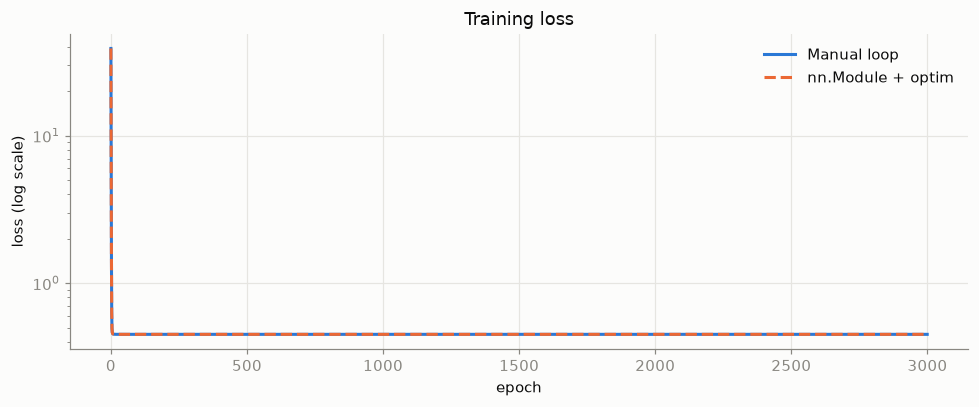

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(manual_losses, color=BLUE, linewidth=2, label="Manual loop")
ax.plot(std_losses, color=ORANGE, linewidth=2, linestyle="--", label="nn.Module + optim")
ax.set(title="Training loss", xlabel="epoch", ylabel="loss (log scale)", yscale="log")
ax.legend(frameon=False)
fig.tight_layout()
show(fig, "loss_curves")

## 9. Test-set comparison
Baselines (no model): the training-set **median** count for every hour, and
the training-set median for each hour-of-day × weekend combination.

In [11]:
def predict_all(split):
    with torch.no_grad():
        manual = (Xt[split] @ manual_w + manual_b).squeeze(1).numpy()
        standard = std_model(Xt[split]).squeeze(1).numpy()
    return {
        "scikit-learn": to_bikes(sk_model.predict(X[split]), TARGET),
        "manual PyTorch": to_bikes(manual, TARGET),
        "standard PyTorch": to_bikes(standard, TARGET),
    }


train_df = df[masks["train"]]
test_df = df[masks["test"]]
hour_medians = train_df.groupby(["hour", "weekend"])["count"].median()

test_preds = {
    "baseline: median": np.full(len(test_df), train_df["count"].median()),
    "baseline: hour x weekend median": hour_medians.loc[
        list(zip(test_df["hour"], test_df["weekend"]))].to_numpy(),
    **predict_all("test"),
}

rows = []
for name, pred in test_preds.items():
    rows.append({
        "model": name,
        "MAE": mean_absolute_error(counts["test"], pred),
        "RMSE": np.sqrt(mean_squared_error(counts["test"], pred)),
        "R2": r2_score(counts["test"], pred),
    })
results = pd.DataFrame(rows).set_index("model").round(3)
print(results.to_string())

                                     MAE     RMSE     R2
model                                                   
baseline: median                 505.088  652.100 -0.033
baseline: hour x weekend median  423.008  544.105  0.281
scikit-learn                     241.737  367.558  0.672
manual PyTorch                   241.737  367.558  0.672
standard PyTorch                 241.737  367.558  0.672


### Do the three implementations agree?

In [12]:
coefs = pd.DataFrame({
    "scikit-learn": np.append(sk_model.coef_, sk_model.intercept_),
    "manual PyTorch": np.append(manual_w.squeeze(1).numpy(), manual_b.numpy()),
    "standard PyTorch": np.append(std_model.linear.weight.detach().squeeze(0).numpy(),
                                  std_model.linear.bias.detach().numpy()),
}, index=FEATURES + ["intercept"])
print(coefs.round(4).to_string())

sk_pred = test_preds["scikit-learn"]
agreement = {
    f"max |coef diff| {name} vs scikit-learn": float((coefs[name] - coefs["scikit-learn"]).abs().max())
    for name in ["manual PyTorch", "standard PyTorch"]
}
agreement |= {
    f"max |prediction diff| {name} vs scikit-learn (bikes)": float(np.abs(test_preds[name] - sk_pred).max())
    for name in ["manual PyTorch", "standard PyTorch"]
}
agreement["max |coef diff| manual vs standard PyTorch"] = float(
    (coefs["manual PyTorch"] - coefs["standard PyTorch"]).abs().max())
for k, v in agreement.items():
    print(f"{k}: {v:.6f}")

                     scikit-learn  manual PyTorch  standard PyTorch
hour_sin1                 -0.3442         -0.3442           -0.3442
hour_cos1                 -0.0566         -0.0566           -0.0566
hour_sin2                 -0.3782         -0.3782           -0.3782
hour_cos2                 -0.1139         -0.1139           -0.1139
weekend                   -0.0789         -0.0789           -0.0789
weekend_x_hour_sin1       -0.0674         -0.0674           -0.0674
weekend_x_hour_cos1        0.0480          0.0480            0.0480
weekend_x_hour_sin2        0.1437          0.1437            0.1437
weekend_x_hour_cos2        0.1267          0.1267            0.1267
holiday                   -0.0293         -0.0293           -0.0293
temp                       0.3525          0.3525            0.3525
solar                      0.1711          0.1711            0.1711
rain                      -0.3156         -0.3156           -0.3156
snow                      -0.0703         -0.070

## 10. Save artifacts for the dashboard

In [13]:
joblib.dump(sk_model, ARTIFACTS / "sklearn_ridge.joblib")
joblib.dump(scaler, ARTIFACTS / "scaler.joblib")
torch.save({"w": manual_w, "b": manual_b}, ARTIFACTS / "manual_pytorch.pt")
torch.save(std_model.state_dict(), ARTIFACTS / "standard_pytorch.pt")

df.to_csv(ARTIFACTS / "data_with_split.csv", index=False)
results.to_csv(ARTIFACTS / "test_metrics.csv")
coefs.to_csv(ARTIFACTS / "coefficients.csv")
pd.DataFrame({"manual PyTorch": manual_losses, "standard PyTorch": std_losses}).to_csv(
    ARTIFACTS / "loss_curves.csv", index_label="epoch")

config = {
    "features": FEATURES,
    "target": TARGET,
    "alpha": ALPHA,
    "manual_lr": MANUAL_LR,
    "standard_lr": STANDARD_LR,
    "epochs": EPOCHS,
    "target_check_val_mae": target_check,
    "alpha_val_mae": {str(k): v for k, v in alpha_results.items()},
    "manual_lr_val_mae": {str(k): v for k, v in manual_lr_results.items()},
    "standard_lr_val_mae": {str(k): v for k, v in standard_lr_results.items()},
    "agreement": agreement,
}
(ARTIFACTS / "config.json").write_text(json.dumps(config, indent=2))
print("Saved:", sorted(p.name for p in ARTIFACTS.iterdir()))

Saved: ['coefficients.csv', 'config.json', 'data_with_split.csv', 'figures', 'loss_curves.csv', 'manual_pytorch.pt', 'scaler.joblib', 'sklearn_ridge.joblib', 'standard_pytorch.pt', 'test_metrics.csv']
